# CLASSICAL HYDRO SOLVER IN 1D, SOD'S SHOCKTUBE

In [1]:
from matplotlib import pyplot as plt
import numpy as np

$$ \partial_t \rho + \partial_x (\rho u) = 0 $$

$$ \partial_t (\rho u) + \partial_x (\rho u u) = - \partial_x p$$

$$ \partial_t (\rho \epsilon_{tot}) + \partial_x (\rho \epsilon_{tot} u) = - \partial_x (pu)$$

$$ p = (\gamma -1)\rho \epsilon$$

$$ c_s = \sqrt{\gamma(\gamma-1)\epsilon}$$

$$ \rho \epsilon_{tot} = \rho \epsilon_{int} + \rho \frac{u^2}{2}$$

## SET UP VARIABLES AND GRID

In [ ]:

x = np.linspace(0,100,500)
dx = (100.0 -0.0)/(500 -1)
t_start = 0.0
t_end = 40.0
courant  = 0.5
gamma = 1.40

In [5]:
#comment out what stays same
initial_rho = np.zeros(len(x))
initial_rho[0:250] = 2.0
initial_rho[250:] = 1.0

initial_u = np.zeros(len(initial_rho))
initial_mom = initial_rho*initial_u #just array of zeroes for u = 0

initial_internal = 1.0 
initial_energy = initial_rho*initial_internal + (initial_rho*initial_u**2.0)/2.0
# so since intial_internal 1.0 and initial_u =0, initial energy and initial rho are the same...

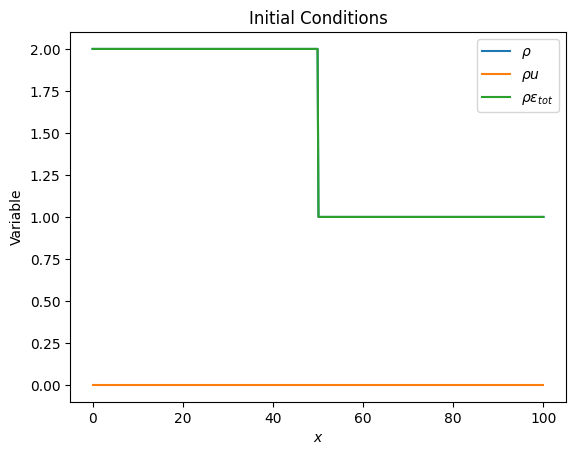

In [6]:
plt.plot(x, initial_rho, label=r'$\rho$')
plt.plot(x, initial_mom, label=r'$\rho u$')
plt.plot(x, initial_energy, label=r'$\rho \epsilon_{tot}$')
plt.xlabel(r'$x$')
plt.ylabel('Variable')
plt.title('Initial Conditions')
plt.legend()

## HELPER FUNCTIONS

In [98]:
#tiime step using full grid info

def get_dt(c_s, rho, mom, courant,dx):
    nu_max = np.max(c_s + np.abs(mom/rho))
    return courant*dx/nu_max

#sound speed on entire grid

def get_c_s(rho,mom,energy, gamma):
    epsilon_tot = energy/rho
    speed = mom/rho
    
    epsilon_int = epsilon_tot - (speed**2.0)/2.0
    
    return np.sqrt(gamma*(gamma-1)*epsilon_int)

#pressure

def get_pressure(gamma, rho, mom, energy):
    speed = mom/rho
    epsilon_tot = energy/rho
    
    epsilon_int = epsilon_tot - (speed**2.0)/2.0
    
    return (gamma-1)*rho*epsilon_int

In [172]:
ksi = 3.

def artificial_pressure(u_m, u_p, rho, key):
    art_pressure = np.zeros(len(x))

    if key == 1: #positive/right-sided pressure
        for i in range(1, len(x)-1):
            if u_p[i+1] <= u_m[i+1]:
                art_pressure[i] =  0.25*rho[i+1]*(ksi*(u_p[i+1] - u_m[i+1]))**2.0
    
    elif key == 2: #negative/left-sided pressure
        for i in range(1, len(x)-1):
            if u_p[i-1] <= u_m[i-1]:
                art_pressure[i] =  0.25*rho[i-1]*(ksi*(u_p[i-1] - u_m[i-1]))**2.0

    return art_pressure

        

## MAIN FUNCTION

In [173]:

def hydro_upwind_solver():

    #make copies of initial data so as to not mutate initial data lists
    rho = np.copy(initial_rho)
    mom = np.copy(initial_mom)
    energy = np.copy(initial_energy)

    #these will store data from all time slices
    rhos = []
    rhos.append(initial_rho)
    moms = []
    moms.append(initial_mom)
    energies = []
    energies.append(initial_energy)
    time = [t_start]
    t = t_start

    #for stroing fluxes
    u_p = np.zeros(len(x))
    u_m = np.zeros(len(x))

    f_p_rho = np.zeros(len(x))
    f_p_mom = np.zeros(len(x))
    f_p_energy = np.zeros(len(x))

    f_m_rho = np.zeros(len(x))
    f_m_mom = np.zeros(len(x))
    f_m_energy = np.zeros(len(x))

    #pressure
    p_p = np.zeros(len(x))
    p_m = np.zeros(len(x))

    while t < t_end:
        #get allowed time step
        c_s = get_c_s(rho, mom, energy, gamma)
        dt = get_dt(c_s,rho,mom,courant,dx)

        #find fluxes
        u_p[:] = 0.
        u_m[:] = 0.
        f_p_rho[:] = 0.
        f_p_mom[:] = 0.
        f_p_energy[:] = 0.
        f_m_rho[:] = 0.
        f_m_mom[:] = 0.
        f_m_energy[:] = 0.

        u_p[1:-1] = 0.5*((mom[1:-1]/rho[1:-1])+(mom[2:]/rho[2:]))
        u_m[1:-1] = 0.5*((mom[0:-2]/rho[0:-2])+(mom[1:-1]/rho[1:-1]))

        for i in range(1, len(x)-1):
            if u_p[i] >= 0:
                f_p_rho[i] = rho[i]*u_p[i] 
                f_p_mom[i] = mom[i]*u_p[i]
                f_p_energy[i] = energy[i]*u_p[i]
            else:
                f_p_rho[i] = rho[i+1]*u_p[i]
                f_p_mom[i] = mom[i+1]*u_p[i]
                f_p_energy[i] = energy[i+1]*u_p[i]

            if u_m[i] >= 0:
                f_m_rho[i] = rho[i-1]*u_m[i]
                f_m_mom[i] = mom[i-1]*u_m[i]
                f_m_energy[i] = energy[i-1]*u_m[i]
            else:
                f_m_rho[i] = rho[i]*u_m[i]
                f_m_mom[i] = mom[i]*u_m[i]
                f_m_energy[i] = energy[i]*u_m[i]


        #these are half way values    
        rho[1:-1] = rho[1:-1] - (dt/dx)*(f_p_rho[1:-1] - f_m_rho[1:-1])
        mom[1:-1] = mom[1:-1] - (dt/dx)*(f_p_mom[1:-1] - f_m_mom[1:-1])
        energy[1:-1] = energy[1:-1] - (dt/dx)*(f_p_energy[1:-1] - f_m_energy[1:-1])
            
        #reflective boundaries
        rho[0] = rho[1]
        mom[0] = - mom[1]
        energy[0] = energy[1]
        rho[len(x)-1] = rho[len(x)-2]
        mom[len(x)-1] = - mom[len(x)-2]
        energy[len(x)-1] =  energy[len(x)-2]

        #adding forcing term
        u_p[:] = 0.
        u_m[:] = 0.
        p_p[:] = 0.
        p_m[:] = 0.

        u_p[1:-1] = mom[2:]/rho[2:]
        u_m[1:-1] = mom[0:-2]/rho[0:-2]
        
        p_p[1:-1] = get_pressure(gamma, rho[2:], mom[2:], energy[2:]) + artificial_pressure(u_m, u_p, rho, 1)[1:-1]
        p_m[1:-1] = get_pressure(gamma, rho[0:-2], mom[0:-2], energy[0:-2]) +artificial_pressure(u_m, u_p, rho, 2)[1:-1]
        
 
        #these are complete values after operator splitting
        #rho does not change
        mom[1:-1] = mom[1:-1] - 0.5*(dt/dx)*(p_p[1:-1] - p_m[1:-1])
        energy[1:-1] = energy[1:-1] - 0.5*(dt/dx)*(p_p[1:-1]*u_p[1:-1] - p_m[1:-1]*u_m[1:-1])
            
        #reflective boundaries
        rho[0] = rho[1]
        mom[0] = - mom[1]
        energy[0] =  energy[1]
        rho[len(x)-1] = rho[len(x)-2]
        mom[len(x)-1] = - mom[len(x)-2]
        energy[len(x)-1] =  energy[len(x)-2]
        
        rho_copy = np.copy(rho) #this is necessary so that the appended list does not change!
        rhos.append(rho_copy)
        
        mom_copy = np.copy(mom) #this is necessary so that the appended list does not change!
        moms.append(mom_copy)
        
        energy_copy = np.copy(energy)
        energies.append(energy_copy)

        t = t + dt 
        time.append(t)
        

    return rhos, moms, energies, time

In [174]:
rhos, moms, energies, time = hydro_upwind_solver()



In [175]:
print(len(time))

394


In [176]:
rhos = np.array(rhos)
moms = np.array(moms)
energies = np.array(energies)

In [177]:
speeds = moms/rhos

In [178]:
internal_energies = energies/rhos - 0.5*(speeds**2.0)

## MAKE MOVIE

In [124]:
from matplotlib.animation import PillowWriter

In [179]:
def plot_frame(index, ax):
    
    density = ax[0]
    speed = ax[1]
    internal_energy = ax[2]

    density.plot(x, rhos[index, :])
    density.grid(True)
    density.set_ylabel(r'$\rho$')
    density.set_ylim([0.9, 2.1])
    density.tick_params(bottom = False, labelbottom = False)

    speed.plot(x, speeds[index, :])
    speed.grid(True)
    speed.set_ylabel(r'$u$')
    speed.set_ylim([-0.025, 0.225])
    speed.tick_params(bottom = False, labelbottom=False)

    internal_energy.plot(x, internal_energies[index])
    internal_energy.grid(True)
    internal_energy.set_xlabel(r'$x$')
    internal_energy.set_ylabel(r'$\epsilon_{int}$')
    internal_energy.set_ylim([0.875, 1.125])

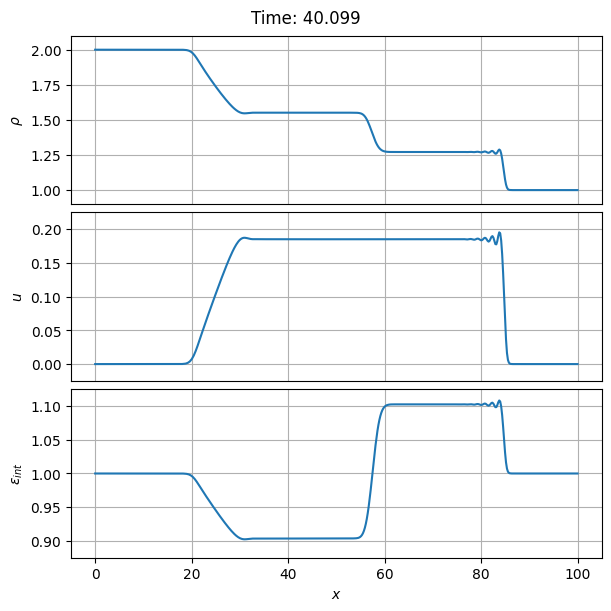

In [182]:
fig, ax = plt.subplots(3,1, sharex=True, figsize=(6, 6), constrained_layout=True)
fig.suptitle('Time: '+str("%.3f" %(time[-1])))
#fig.patch.set_facecolor('black')
plot_frame(-1,ax)
plt.show()

In [139]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

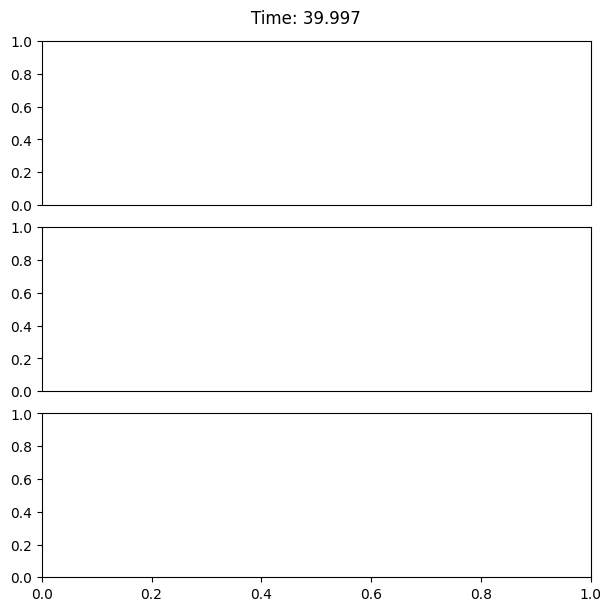

In [183]:
fig, ax = plt.subplots(3,1, sharex=True, figsize=(6, 6), constrained_layout=True)
#fig.patch.set_facecolor('black')

with writer.saving(fig, 'sods_shocktube_viscosity.gif',100):
    for i in range(0, len(time)):
        if i%2 == 0:
            fig.suptitle('Time: '+str("%.3f" %(time[i])))
            plot_frame(i, ax)
            writer.grab_frame()
            ax[0].clear()
            ax[1].clear()
            ax[2].clear()